# Exploration: how wind and solar move the German electricity price

Purpose: find the story for the dashboard before building it. This notebook only **reads** the marts the pipeline produces; all cleaning and testing happens in dbt.

Leading question (from `SCOPE.md`): **How much do wind and solar push down the German day-ahead price, and when do they push it below zero?**

Data: `data/marts/*.parquet`. Run `make pull-data` (or `make pipeline`) first. Numbers in the text are as of 20 October 2026; 2026 is a partial year.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MARTS = Path("../data/marts")

# Colours: first three categorical slots of the reference palette (validated for
# colour-blind safety as a set), recessive ink and grid.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

hours = duckdb.sql(f"""
    select *,
           (generation_wind + generation_solar) / grid_load as wind_solar_share,
           year(date_local) as year,
           month(date_local) as month,
           isodow(date_local) >= 6 as is_weekend
    from read_parquet('{MARTS}/fct_hours.parquet')
    where is_complete
""").df()
print(f"{len(hours):,} complete hours, {hours.date_local.min()} to {hours.date_local.max()}")

70,512 complete hours, 2018-10-01 00:00:00 to 2026-10-16 00:00:00


## 1. The big picture, year by year

Average price, hours with a negative price and the renewable share of consumption.

In [2]:
yearly = hours.groupby("year").agg(
    avg_price=("price_day_ahead", "mean"),
    negative_hours=("price_day_ahead", lambda p: (p < 0).sum()),
    renewable_share=("generation_renewable", "sum"),
    load=("grid_load", "sum"),
)
yearly["renewable_share"] = yearly.renewable_share / yearly.load
yearly = yearly.drop(columns="load")
yearly.style.format({"avg_price": "{:.1f} €/MWh", "renewable_share": "{:.0%}"})

,avg_price,negative_hours,renewable_share
year,,,
2018,52.6 €/MWh,27,41%
2019,37.7 €/MWh,211,45%
2020,30.5 €/MWh,298,48%
2021,96.8 €/MWh,139,42%
2022,235.4 €/MWh,69,48%
2023,95.2 €/MWh,301,55%
2024,78.5 €/MWh,457,55%
2025,89.3 €/MWh,576,55%
2026,110.8 €/MWh,472,61%


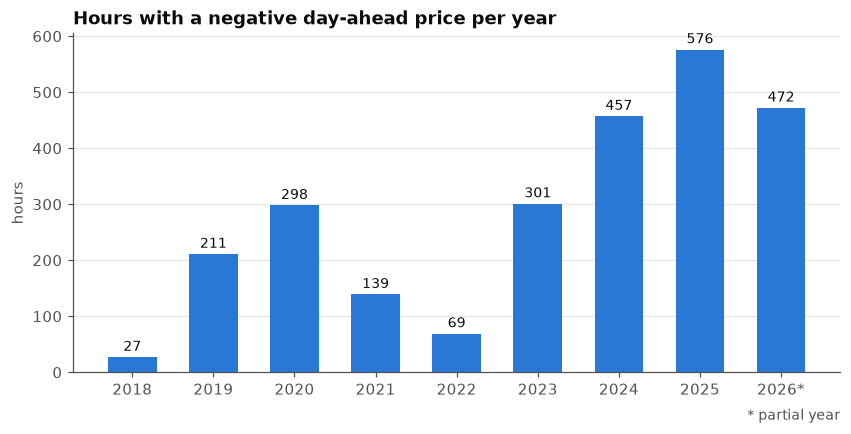

In [3]:
fig, ax = plt.subplots()
bars = ax.bar(yearly.index, yearly.negative_hours, color=BLUE, width=0.6)
ax.bar_label(bars, color=INK, fontsize=9, padding=2)
ax.set_title("Hours with a negative day-ahead price per year")
ax.set_ylabel("hours")
ax.set_xticks(yearly.index, [f"{y}*" if y == yearly.index.max() else str(y) for y in yearly.index])
ax.grid(axis="x", visible=False)
ax.text(1, -0.14, "* partial year", transform=ax.transAxes, ha="right", color=MUTED, fontsize=9)
plt.show()

**Reading:** negative hours have grown from a rare event (27 in the last quarter of 2018) to a regular one: 457 in 2024 and 576 in 2025. They follow the renewable share, which rose from about 41 % to 55 % (2023–2025) and 61 % so far in 2026.

The price **level** tells a different story: 2022 averaged 235 €/MWh at the same renewable share as 2020 (30 €/MWh). That is the gas crisis, and the reason the gas price is the main open extension in `SCOPE.md`.

## 2. When does the price turn negative?

Share of hours with a negative price, by how much of consumption wind and solar cover in that hour (2023 onwards, after the gas crisis).

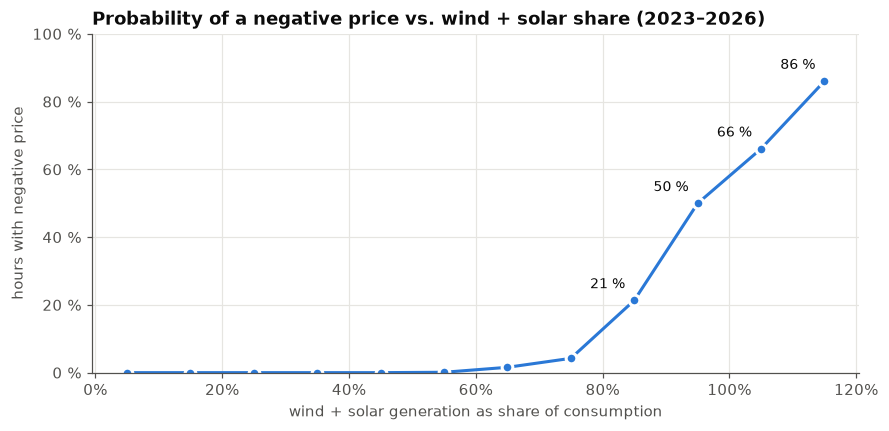

,hours,negative,median_price
share_bin,,,
"(0.0, 0.1]",2343,0.0%,131 €/MWh
"(0.1, 0.2]",4386,0.0%,125 €/MWh
"(0.2, 0.3]",4564,0.0%,113 €/MWh
"(0.3, 0.4]",4555,0.0%,105 €/MWh
"(0.4, 0.5]",4326,0.0%,94 €/MWh
"(0.5, 0.6]",3639,0.1%,83 €/MWh
"(0.6, 0.7]",3181,1.6%,70 €/MWh
"(0.7, 0.8]",2346,4.2%,48 €/MWh
"(0.8, 0.9]",1768,21.3%,10 €/MWh


In [4]:
recent = hours[hours.year >= 2023].copy()
edges = np.arange(0, 1.25, 0.1)
recent["share_bin"] = pd.cut(recent.wind_solar_share, edges)
by_share = recent.groupby("share_bin", observed=True).agg(
    hours=("price_day_ahead", "size"),
    negative=("price_day_ahead", lambda p: (p < 0).mean()),
    median_price=("price_day_ahead", "median"),
)
by_share = by_share[by_share.hours >= 100]  # drop bins too thin to read
mid = [iv.mid for iv in by_share.index]

fig, ax = plt.subplots()
ax.plot(mid, by_share.negative * 100, color=BLUE, marker="o", markersize=7,
        markeredgecolor="white", markeredgewidth=2)
for x, y in zip(mid, by_share.negative * 100):
    if y >= 10:
        ax.annotate(f"{y:.0f} %", (x, y), textcoords="offset points", xytext=(-6, 8),
                    ha="right", color=INK, fontsize=9)
ax.set_title("Probability of a negative price vs. wind + solar share (2023–2026)")
ax.set_xlabel("wind + solar generation as share of consumption")
ax.set_ylabel("hours with negative price")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f} %")
ax.set_ylim(0, 100)
plt.show()
by_share.style.format({"negative": "{:.1%}", "median_price": "{:.0f} €/MWh"})

**Reading:** below a wind + solar share of about 60 % the price is practically never negative. From there the probability rises steeply: about 4 % at 70–80 %, 21 % at 80–90 %, 50 % at 90–100 %, and 66 % to 86 % when wind and solar produce more than Germany consumes.

So the threshold is not "a lot of renewables" but **renewables close to covering the whole load**: then conventional plants that cannot ramp down, and subsidised plants that are paid regardless, push the price below zero.

## 3. The merit order: price vs. residual load

Residual load = consumption minus wind and solar, i.e. what conventional plants have to cover. The median price per 10 GW band, separately for three periods.

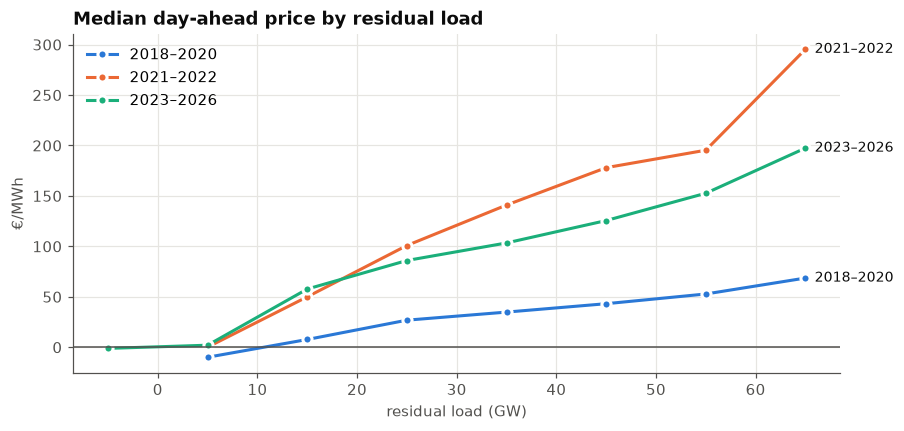

In [5]:
eras = {"2018–2020": (2018, 2020, BLUE), "2021–2022": (2021, 2022, ORANGE), "2023–2026": (2023, 2026, AQUA)}
hours["residual_gw"] = hours.residual_load / 1000  # MWh per hour -> average GW

fig, ax = plt.subplots()
for label, (first, last, colour) in eras.items():
    d = hours[hours.year.between(first, last)]
    curve = d.groupby(pd.cut(d.residual_gw, np.arange(-20, 90, 10)), observed=True).agg(
        price=("price_day_ahead", "median"), hours=("price_day_ahead", "size"))
    curve = curve[curve.hours >= 50]
    x = [iv.mid for iv in curve.index]
    ax.plot(x, curve.price, color=colour, label=label, marker="o", markersize=6,
            markeredgecolor="white", markeredgewidth=2)
    ax.annotate(label, (x[-1], curve.price.iloc[-1]), textcoords="offset points",
                xytext=(6, 0), va="center", color=INK, fontsize=9)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_title("Median day-ahead price by residual load")
ax.set_xlabel("residual load (GW)")
ax.set_ylabel("€/MWh")
ax.legend(loc="upper left")
plt.show()

**Reading:** in every period the price rises with residual load, the classic merit order: the more conventional plants are needed, the more expensive the last one that sets the price. Wind and solar move the market **along** this curve.

The **height** of the curve depends on the fuel price: at 40–50 GW residual load the median was about 43 €/MWh in 2018–2020, 178 € in 2021–2022 and 126 € since 2023. Since 2023, residual loads below zero exist at all, and that is exactly where the negative prices are.

## 4. How much does +10 percentage points of wind and solar lower the price?

To separate the renewable effect from the fuel price level, each hour is compared with the average of its own month (a within-month regression: both price and wind + solar share are de-meaned per calendar month, then the slope is estimated). This removes slow changes like the gas price, but not short-term ones such as weekday patterns, so it is a descriptive estimate, not a causal one.

In [6]:
rows = []
for label, (first, last, _) in eras.items():
    d = hours[hours.year.between(first, last)]
    group = d.groupby(["year", "month"])
    y = d.price_day_ahead - group.price_day_ahead.transform("mean")
    x = d.wind_solar_share - group.wind_solar_share.transform("mean")
    slope = (x * y).sum() / (x * x).sum()
    rows.append({"period": label,
                 "€/MWh per +10 pp wind + solar": slope / 10,
                 "correlation": np.corrcoef(x, y)[0, 1],
                 "avg price": d.price_day_ahead.mean()})
effect = pd.DataFrame(rows).set_index("period")
effect.style.format({"€/MWh per +10 pp wind + solar": "{:.1f}", "correlation": "{:.2f}", "avg price": "{:.0f} €/MWh"})

,€/MWh per +10 pp wind + solar,correlation,avg price
period,,,
2018–2020,-5.8,-0.70,36 €/MWh
2021–2022,-26.5,-0.62,166 €/MWh
2023–2026,-15.9,-0.79,92 €/MWh


**Reading:** within a month, 10 percentage points more wind and solar go along with a price that is about **6 €/MWh lower in 2018–2020, 27 € in 2021–2022 and 16 € since 2023**. The correlation is strong in every period (−0.6 to −0.8).

The effect is not a fixed number: it scales with the price of what renewables replace. When gas is expensive, every MWh of wind displaces an expensive MWh, so the "merit-order effect" was largest during the gas crisis. That is a strong point for the dashboard, and again a reason to add a gas price later.

## 5. When in the day and year do negative prices happen?

Number of negative hours by hour of day and month, 2024 to today.

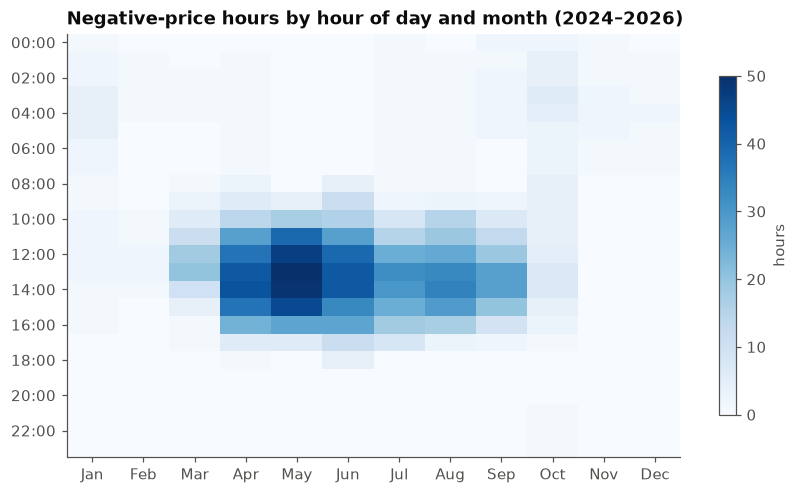

Share of hours with a negative price: weekdays 3.5%, weekends 12.8%


In [7]:
recent = hours[hours.year >= 2024]
negative = recent[recent.price_day_ahead < 0]
grid = (negative.pivot_table(index="hour_of_day_local", columns="month", values="price_day_ahead", aggfunc="size")
        .reindex(index=range(24), columns=range(1, 13)).fillna(0))

fig, ax = plt.subplots(figsize=(9, 5))
image = ax.imshow(grid, cmap="Blues", aspect="auto", origin="upper")
ax.set_title("Negative-price hours by hour of day and month (2024–2026)")
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.grid(False)
fig.colorbar(image, ax=ax, label="hours", shrink=0.8)
plt.show()

weekend = recent.groupby("is_weekend").price_day_ahead.apply(lambda p: (p < 0).mean())
print(f"Share of hours with a negative price: weekdays {weekend[False]:.1%}, weekends {weekend[True]:.1%}")

**Reading:** negative prices are a **solar** phenomenon. They cluster between 10:00 and 16:00, from April to September, with the peak in May and June. Winter and night hours are almost never negative, even though winter is the windier season: at night and in winter consumption is high enough to absorb the wind.

Weekends are almost four times as likely to have negative hours as weekdays (12.8 % vs. 3.5 % of hours), because industry consumes less while the sun produces the same.

## 6. Quarter-hour prices since October 2025

Since 1 October 2025 the day-ahead market trades quarter hours. What does the hourly view hide?

In [8]:
qh = duckdb.sql(f"""
    with by_hour as (
        select date_trunc('hour', ts_utc) as hour,
               avg(price_day_ahead) as avg_price,
               min(price_day_ahead) as min_price,
               max(price_day_ahead) - min(price_day_ahead) as spread
        from read_parquet('{MARTS}/fct_quarter_hours.parquet')
        where has_quarter_hour_price
        group by 1
    )
    select count(*) as hours,
           median(spread) as median_spread_within_hour,
           quantile_cont(spread, 0.9) as p90_spread_within_hour,
           count(*) filter (where min_price < 0) as hours_with_a_negative_quarter_hour,
           count(*) filter (where avg_price < 0) as hours_negative_on_average
    from by_hour
""").df().T
qh.columns = ["value"]
qh.style.format("{:,.1f}")

,value
hours,"9,239.0"
median_spread_within_hour,15.3
p90_spread_within_hour,55.3
hours_with_a_negative_quarter_hour,622.0
hours_negative_on_average,522.0


**Reading:** within a single hour the four quarter-hour prices differ by a median of 15 €/MWh (90th percentile: 55 €). And 622 hours had at least one negative quarter hour, but only 522 were negative on average: **an hourly view misses about one in six negative events**. The dashboard should therefore show quarter hours for recent periods and hours for long-term comparisons.

## 7. Takeaways for the dashboard

The story in four views:

1. **Trend:** negative hours per year next to the renewable share (section 1).
2. **Threshold:** probability of a negative price vs. wind + solar share. The tipping point is around 80 % of consumption (section 2).
3. **Mechanism:** the merit-order curve per period. Wind and solar move the market along the curve, fuel prices move the curve (sections 3 and 4).
4. **Pattern:** heatmap hour × month, plus a "latest days" view at quarter-hour resolution (sections 5 and 6).

**Limitations to state on the dashboard:**

- No gas or CO₂ prices: the size of the renewable effect depends on them (section 4), so the effect is shown per period, not as one number.
- The within-month regression is descriptive: weekday and holiday patterns are not controlled for.
- Imports and exports are not in the data; a wind + solar share above 100 % means Germany exports or curtails.